# Model 5: CNN-BiLSTM-Attention

**Model 5 of 7** in the NLP Sentiment Benchmark (Part A).

This notebook is **self-contained** — upload it to Kaggle as-is, add a GPU accelerator (T4 x1 or x2), and run all cells top to bottom. No other files needed.

At the end it saves the trained model + tokenizer + MLflow logs to `/kaggle/working/` — download those before your Kaggle session expires.

**This is the primary custom architecture** — it combines all three ideas: a Conv1D layer for local n-gram features, a BiLSTM for sequential context, and a self-attention layer that learns *which words matter most* for the final prediction (and lets us visualize that at the end).

In [1]:
# Install the few packages Kaggle doesn't ship by default.
# torch / pandas / numpy / matplotlib / scikit-learn are already on Kaggle images.
!pip install -q mlflow seaborn

In [2]:
import os
import re
import ast
import time
import random
import pickle
import logging
from collections import Counter
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt   # uses Jupyter's inline backend on Kaggle — plots render in the notebook
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import mlflow

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
log = logging.getLogger(__name__)

/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# ══════════════════════════════════════════════════════════════
# CONFIG — every constant this notebook needs lives here.
# Change a value once, it affects the whole notebook.
# ══════════════════════════════════════════════════════════════
LABEL2ID = {"positive": 0, "neutral": 1, "negative": 2}
ID2LABEL = {0: "positive", 1: "neutral", 2: "negative"}
NUM_LABELS = 3

VOCAB_SIZE = 30_000     # top-N most frequent words kept in the tokenizer
MAX_LENGTH = 128        # every headline is padded/truncated to this many tokens
PAD_TOKEN, UNK_TOKEN = "<PAD>", "<UNK>"
PAD_IDX, UNK_IDX = 0, 1

SEED = 42
BATCH_SIZE = 64
NUM_EPOCHS = 15
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.01
PATIENCE = 3            # early-stopping patience, measured on val F1-weighted

TEST_SIZE = 0.15        # fraction of full data held out as test
VAL_SIZE = 0.10         # fraction of full data held out as val

MLFLOW_EXPERIMENT = "IndianFinSentiment"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

# Works whether you're on Kaggle or running this locally.
BASE_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
RESULTS_DIR = os.path.join(BASE_DIR, "results")
MODELS_DIR = os.path.join(BASE_DIR, "saved_models")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

# MLflow 3.x defaults to a SQLite-backed store (metrics/params live INSIDE
# mlflow.db, not as flat files) unless it finds existing file-store data.
# We pin the db to a known path so it's easy to find and download afterwards.
mlflow.set_tracking_uri(f"sqlite:///{os.path.join(BASE_DIR, 'mlflow.db')}")

Using device: cpu


## 1. Load data

**Dataset: SEntFiN-v1.1** — 10,753 Indian financial news headlines with entity-level sentiment.

On Kaggle: click **Add Data** and upload/attach `SEntFiN-v1.1.csv` as a dataset input before running this notebook.
Locally: this reads from `../data/raw/SEntFiN-v1.1.csv`.

In [4]:
# ══════════════════════════════════════════════════════════════
# DATA LOADING — SEntFiN-v1.1 (Indian financial headlines, entity-level sentiment)
# ══════════════════════════════════════════════════════════════

def resolve_sentifin_path() -> str:
    candidates = ["../data/raw/SEntFiN-v1.1.csv", "../data/SEntFiN-v1.1.csv"]
    if os.path.isdir("/kaggle/input"):
        for root, _, files in os.walk("/kaggle/input"):
            for f in files:
                if f == "SEntFiN-v1.1.csv":
                    candidates.insert(0, os.path.join(root, f))
    for path in candidates:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(
        "SEntFiN-v1.1.csv not found. On Kaggle: Add Data -> upload SEntFiN-v1.1.csv as a "
        "dataset and attach it to this notebook. Locally: place it at data/raw/SEntFiN-v1.1.csv."
    )


def load_sentifin() -> pd.DataFrame:
    """
    SEntFiN-v1.1 — 10,753 Indian financial headlines with entity-level sentiment,
    e.g. Decisions = {"SpiceJet": "neutral"}. ~26% of headlines mention >1 entity.
    Since this notebook classifies a whole headline as one label (not entity-aware),
    we keep headlines where every entity shares one sentiment (trivially true for
    single-entity headlines) and drop the ~11.5% where entities disagree — those are
    ambiguous for a single-label classifier.
    """
    log.info("Loading SEntFiN-v1.1...")
    raw = pd.read_csv(resolve_sentifin_path())

    texts, labels, n_entities = [], [], []
    dropped = 0
    for _, row in raw.iterrows():
        try:
            decisions = ast.literal_eval(row["Decisions"])
        except (ValueError, SyntaxError):
            continue
        if not decisions:
            continue
        unique_labels = set(decisions.values())
        if len(unique_labels) != 1:
            dropped += 1
            continue
        texts.append(row["Title"])
        labels.append(unique_labels.pop())
        n_entities.append(len(decisions))

    df = pd.DataFrame({"text": texts, "label": labels, "n_entities": n_entities})
    df["label"] = df["label"].str.lower().str.strip()
    df = df[df["label"].isin(LABEL2ID.keys())]
    df["label_id"] = df["label"].map(LABEL2ID)
    df["source"] = "sentifin"
    log.info(f"  Loaded {len(df)} headlines (dropped {dropped} with conflicting entity sentiment)")
    return df[["text", "label", "label_id", "source", "n_entities"]]


def load_and_combine() -> pd.DataFrame:
    """Load SEntFiN, clean, dedupe. Returns one clean DataFrame."""
    df = load_sentifin()

    df = df.dropna(subset=["text", "label_id"])
    df["text"] = df["text"].astype(str).str.strip()
    df = df[df["text"].str.len() > 10]         # drop near-empty rows
    df = df[df["text"].str.len() < 1000]       # drop unusually long rows
    df = df.drop_duplicates(subset=["text"])

    log.info(f"Combined dataset: {len(df)} samples")
    for label, count in df["label"].value_counts().items():
        log.info(f"  {label:>10}: {count:>6} ({count/len(df)*100:.1f}%)")

    return df.reset_index(drop=True)


def split_data(df: pd.DataFrame) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Stratified train/val/test split so class balance holds in every split."""
    train_val_df, test_df = train_test_split(
        df, test_size=TEST_SIZE, stratify=df["label_id"], random_state=SEED
    )
    train_df, val_df = train_test_split(
        train_val_df, test_size=VAL_SIZE / (1 - TEST_SIZE),
        stratify=train_val_df["label_id"], random_state=SEED
    )
    log.info(f"Split sizes -> Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
    return train_df.reset_index(drop=True), val_df.reset_index(drop=True), test_df.reset_index(drop=True)


df_all = load_and_combine()
train_df, val_df, test_df = split_data(df_all)

2026-07-19 20:25:58,338 | INFO | Loading SEntFiN-v1.1...


2026-07-19 20:25:58,956 | INFO |   Loaded 9518 headlines (dropped 1235 with conflicting entity sentiment)


2026-07-19 20:25:58,967 | INFO | Combined dataset: 9459 samples


2026-07-19 20:25:58,969 | INFO |      neutral:   3407 (36.0%)


2026-07-19 20:25:58,970 | INFO |     positive:   3352 (35.4%)


2026-07-19 20:25:58,970 | INFO |     negative:   2700 (28.5%)


2026-07-19 20:25:59,001 | INFO | Split sizes -> Train: 7094 | Val: 946 | Test: 1419


## 2. Build tokenizer (word2idx, fit on train only)

In [5]:
# ══════════════════════════════════════════════════════════════
# TOKENIZER — a simple word-level tokenizer built from scratch.
# Why not a HuggingFace tokenizer here? Models 1-6 use this custom
# tokenizer so every step (vocab, encoding, padding) is visible and
# explainable. Only Model 7 (FinBERT) uses a pretrained BERT tokenizer.
# ══════════════════════════════════════════════════════════════

class FinancialTokenizer:
    """
    Usage:
        tokenizer = FinancialTokenizer()
        tokenizer.build_vocab(train_texts)          # fit on TRAIN only
        ids = tokenizer.encode("Reliance posts record profit")
    """

    def __init__(self, vocab_size: int = VOCAB_SIZE, max_length: int = MAX_LENGTH):
        self.vocab_size = vocab_size
        self.max_length = max_length
        self.word2idx: Dict[str, int] = {PAD_TOKEN: PAD_IDX, UNK_TOKEN: UNK_IDX}
        self.idx2word: Dict[int, str] = {PAD_IDX: PAD_TOKEN, UNK_IDX: UNK_TOKEN}
        self.vocab_built = False

    def _clean(self, text: str) -> str:
        text = text.lower()
        text = re.sub(r"https?://\S+", "", text)
        text = re.sub(r"[^a-z0-9\s\-\%\.]", " ", text)
        text = re.sub(r"\s+", " ", text).strip()
        return text

    def _tokenize(self, text: str) -> List[str]:
        return self._clean(text).split()

    def build_vocab(self, texts: List[str]) -> None:
        """Fit vocabulary on training texts only (avoid val/test leakage)."""
        counter = Counter()
        for text in texts:
            counter.update(self._tokenize(text))
        most_common = counter.most_common(self.vocab_size - 2)
        for idx, (word, freq) in enumerate(most_common, start=2):
            self.word2idx[word] = idx
            self.idx2word[idx] = word
        self.vocab_built = True
        log.info(f"Vocab built: {len(self.word2idx)} tokens (top word: '{most_common[0][0]}')")

    def encode(self, text: str) -> List[int]:
        if not self.vocab_built:
            raise RuntimeError("Call build_vocab() first!")
        tokens = self._tokenize(text)
        ids = [self.word2idx.get(t, UNK_IDX) for t in tokens]
        ids = ids[: self.max_length]
        ids = ids + [PAD_IDX] * (self.max_length - len(ids))
        return ids

    @property
    def vocab_size_actual(self) -> int:
        return len(self.word2idx)


tokenizer = FinancialTokenizer()
tokenizer.build_vocab(train_df["text"].tolist())

2026-07-19 20:25:59,056 | INFO | Vocab built: 9343 tokens (top word: 'to')


## 3. PyTorch Dataset + DataLoaders + class weights

In [6]:
# ══════════════════════════════════════════════════════════════
# PYTORCH DATASET + DATALOADERS
# ══════════════════════════════════════════════════════════════

class SentimentDataset(Dataset):
    def __init__(self, df: pd.DataFrame, tokenizer: FinancialTokenizer):
        self.texts = df["text"].tolist()
        self.labels = df["label_id"].tolist()
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        return len(self.texts)

    def __getitem__(self, idx: int) -> Dict[str, torch.Tensor]:
        ids = self.tokenizer.encode(self.texts[idx])
        return {
            "input_ids": torch.tensor(ids, dtype=torch.long),
            "labels": torch.tensor(self.labels[idx], dtype=torch.long),
        }


train_loader = DataLoader(SentimentDataset(train_df, tokenizer), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(SentimentDataset(val_df,   tokenizer), batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(SentimentDataset(test_df,  tokenizer), batch_size=BATCH_SIZE, shuffle=False)

# Class weights — the dataset is imbalanced (usually few "negative" rows),
# so we upweight rare classes in the loss instead of letting the model
# just always predict the majority class.
class_counts = train_df["label_id"].value_counts().sort_index().values
class_weights = torch.tensor(len(train_df) / (NUM_LABELS * class_counts), dtype=torch.float32).to(DEVICE)
print(f"Class weights (positive, neutral, negative): {class_weights.tolist()}")

Class weights (positive, neutral, negative): [0.9405993223190308, 0.925505518913269, 1.1677366495132446]


## 4. Model architecture

In [7]:
# ══════════════════════════════════════════════════════════════
# MODEL: CNN-BiLSTM-Attention
#   Embedding -> Conv1D(k=3) + BatchNorm + ReLU -> BiLSTM(128)
#   -> Self-Attention (learns a weight per token) -> weighted sum
#   -> dropout -> Linear(256,3)
# ══════════════════════════════════════════════════════════════

class SelfAttention(nn.Module):
    """
    Learns one importance score per token, turns those scores into
    weights via softmax, then returns a single weighted-sum vector
    (the "context vector") plus the raw attention weights so we can
    plot them later.
    """
    def __init__(self, hidden_dim):
        super().__init__()
        self.attn_score = nn.Linear(hidden_dim, 1)

    def forward(self, lstm_out, pad_mask):
        # lstm_out: (batch, seq_len, hidden_dim)   pad_mask: (batch, seq_len) True where PAD
        scores = self.attn_score(lstm_out).squeeze(-1)      # (batch, seq_len)
        scores = scores.masked_fill(pad_mask, float("-inf"))  # ignore PAD positions
        weights = F.softmax(scores, dim=1)                   # (batch, seq_len), sums to 1 per row

        context = torch.bmm(weights.unsqueeze(1), lstm_out).squeeze(1)  # (batch, hidden_dim)
        return context, weights


class CNNBiLSTMAttention(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, conv_channels=128,
                 lstm_hidden=128, num_classes=3, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)

        self.conv = nn.Conv1d(embed_dim, conv_channels, kernel_size=3, padding=1)
        self.bn = nn.BatchNorm1d(conv_channels)

        self.lstm = nn.LSTM(conv_channels, lstm_hidden, batch_first=True, bidirectional=True)
        self.attention = SelfAttention(lstm_hidden * 2)

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(lstm_hidden * 2, num_classes)

        self._last_attn_weights = None   # cached for get_attention_weights()

    def forward(self, input_ids):
        pad_mask = (input_ids == PAD_IDX)                 # (batch, seq_len)

        x = self.embedding(input_ids)                      # (batch, seq_len, embed_dim)
        x = x.transpose(1, 2)                               # (batch, embed_dim, seq_len)
        x = F.relu(self.bn(self.conv(x)))                   # (batch, conv_channels, seq_len)
        x = x.transpose(1, 2)                               # (batch, seq_len, conv_channels)

        lstm_out, _ = self.lstm(x)                          # (batch, seq_len, lstm_hidden*2)
        context, attn_weights = self.attention(lstm_out, pad_mask)

        self._last_attn_weights = attn_weights.detach()      # stash for visualization

        context = self.dropout(context)
        return self.classifier(context)

    def get_attention_weights(self, input_ids):
        """Run a forward pass and return the per-token attention weights (numpy array)."""
        self.eval()
        with torch.no_grad():
            self.forward(input_ids)
        return self._last_attn_weights.cpu().numpy()


MODEL_NAME = "CNN-BiLSTM-Attention"
MODEL_CONFIG = {"vocab_size": tokenizer.vocab_size_actual, "embed_dim": 128, "conv_channels": 128,
                "lstm_hidden": 128, "num_classes": NUM_LABELS, "dropout": 0.3}
model = CNNBiLSTMAttention(**MODEL_CONFIG).to(DEVICE)
print(model)
print(f"\nTrainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

CNNBiLSTMAttention(
  (embedding): Embedding(9343, 128, padding_idx=0)
  (conv): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(1,))
  (bn): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (attention): SelfAttention(
    (attn_score): Linear(in_features=256, out_features=1, bias=True)
  )
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=256, out_features=3, bias=True)
)

Trainable parameters: 1,510,660


## 5. Train / eval helpers

In [8]:
# ══════════════════════════════════════════════════════════════
# TRAINING / EVAL HELPERS (shared by every custom PyTorch model)
# ══════════════════════════════════════════════════════════════

def compute_metrics(y_true, y_pred) -> dict:
    per_class = f1_score(y_true, y_pred, average=None, labels=[0, 1, 2])
    return {
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "f1_weighted": round(f1_score(y_true, y_pred, average="weighted"), 4),
        "f1_positive": round(per_class[0], 4),
        "f1_neutral": round(per_class[1], 4),
        "f1_negative": round(per_class[2], 4),
    }


def save_confusion_matrix(y_true, y_pred, model_name: str) -> str:
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm_pct, annot=True, fmt=".2%", cmap="Blues",
                xticklabels=["positive", "neutral", "negative"],
                yticklabels=["positive", "neutral", "negative"], ax=ax, linewidths=0.5)
    ax.set_title(f"Confusion Matrix - {model_name}", fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    path = os.path.join(RESULTS_DIR, f"cm_{model_name.lower().replace(' ', '_')}.png")
    plt.tight_layout()
    plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.close()
    return path


def train_one_epoch(model, loader, optimizer, criterion) -> float:
    model.train()
    total_loss = 0.0
    for batch in loader:
        input_ids = batch["input_ids"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        optimizer.zero_grad()
        logits = model(input_ids)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * input_ids.size(0)
    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []
    for batch in loader:
        input_ids = batch["input_ids"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        logits = model(input_ids)
        loss = criterion(logits, labels)
        total_loss += loss.item() * input_ids.size(0)

        all_preds.extend(logits.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    metrics = compute_metrics(all_labels, all_preds)
    return avg_loss, metrics, all_preds, all_labels


def count_parameters(model) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def fit(model, model_name: str, epochs=NUM_EPOCHS, lr=LEARNING_RATE, patience=PATIENCE):
    """
    Full training loop with early stopping on val F1-weighted.
    Logs every epoch to MLflow and returns the best model state.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    best_val_f1 = -1.0
    best_state = None
    epochs_no_improve = 0
    start = time.time()

    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_metrics, _, _ = evaluate(model, val_loader, criterion)

        mlflow.log_metric("train_loss", train_loss, step=epoch)
        mlflow.log_metric("val_loss", val_loss, step=epoch)
        for k, v in val_metrics.items():
            mlflow.log_metric(f"val_{k}", v, step=epoch)

        print(f"Epoch {epoch:>2}/{epochs} | train_loss={train_loss:.4f} | "
              f"val_loss={val_loss:.4f} | val_f1={val_metrics['f1_weighted']:.4f}")

        if val_metrics["f1_weighted"] > best_val_f1:
            best_val_f1 = val_metrics["f1_weighted"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} (no val F1 improvement for {patience} epochs).")
                break

    train_time = time.time() - start
    model.load_state_dict(best_state)   # restore best checkpoint
    return model, train_time

## 6. Train (tracked in MLflow)

In [9]:
mlflow.set_experiment(MLFLOW_EXPERIMENT)
mlflow.start_run(run_name=MODEL_NAME)
mlflow.log_params({
    "model": MODEL_NAME, "embed_dim": 128, "conv_channels": 128, "conv_kernel": 3,
    "lstm_hidden": 128, "dropout": 0.3,
    "lr": LEARNING_RATE, "batch_size": BATCH_SIZE, "max_length": MAX_LENGTH,
})

model, train_time = fit(model, MODEL_NAME)

Epoch  1/15 | train_loss=0.9004 | val_loss=0.7456 | val_f1=0.6650


Epoch  2/15 | train_loss=0.6602 | val_loss=0.6658 | val_f1=0.7030


Epoch  3/15 | train_loss=0.5136 | val_loss=0.6482 | val_f1=0.7285


Epoch  4/15 | train_loss=0.3978 | val_loss=0.6615 | val_f1=0.7472


Epoch  5/15 | train_loss=0.3225 | val_loss=0.6769 | val_f1=0.7385


Epoch  6/15 | train_loss=0.2688 | val_loss=0.6496 | val_f1=0.7613


Epoch  7/15 | train_loss=0.2127 | val_loss=0.7520 | val_f1=0.7137


Epoch  8/15 | train_loss=0.1947 | val_loss=0.7139 | val_f1=0.7303


Epoch  9/15 | train_loss=0.1724 | val_loss=0.7566 | val_f1=0.7381
Early stopping at epoch 9 (no val F1 improvement for 3 epochs).


In [10]:
# ── evaluate on test set with the BEST checkpoint ────────────────
test_loss, test_metrics, test_preds, test_labels = evaluate(model, test_loader, nn.CrossEntropyLoss(weight=class_weights))
n_params = count_parameters(model)

for k, v in test_metrics.items():
    mlflow.log_metric(f"test_{k}", v)
mlflow.log_metric("train_time_seconds", round(train_time, 2))
mlflow.log_metric("param_count", n_params)

cm_path = save_confusion_matrix(test_labels, test_preds, MODEL_NAME)
mlflow.log_artifact(cm_path)

report = classification_report(test_labels, test_preds, target_names=["positive", "neutral", "negative"])
report_path = os.path.join(RESULTS_DIR, f"report_{MODEL_NAME.lower().replace(' ', '_')}.txt")
with open(report_path, "w") as f:
    f.write(f"Model: {MODEL_NAME}\n\n{report}")
mlflow.log_artifact(report_path)

print(f"\n{'='*55}\n  {MODEL_NAME} — TEST RESULTS\n{'='*55}")
print(f"  Accuracy    : {test_metrics['accuracy']:.4f}")
print(f"  F1 Weighted : {test_metrics['f1_weighted']:.4f}")
print(f"  Params      : {n_params:,}")
print(f"  Train time  : {train_time:.1f}s")
print(f"{'='*55}")
print(f"\n{report}")


  CNN-BiLSTM-Attention — TEST RESULTS
  Accuracy    : 0.7259
  F1 Weighted : 0.7265
  Params      : 1,510,660
  Train time  : 633.8s

              precision    recall  f1-score   support

    positive       0.78      0.71      0.74       503
     neutral       0.73      0.72      0.72       511
    negative       0.67      0.75      0.71       405

    accuracy                           0.73      1419
   macro avg       0.73      0.73      0.73      1419
weighted avg       0.73      0.73      0.73      1419



## 7. Attention visualization

Given a headline, show which words the model paid the most attention to (green = high, red = low).

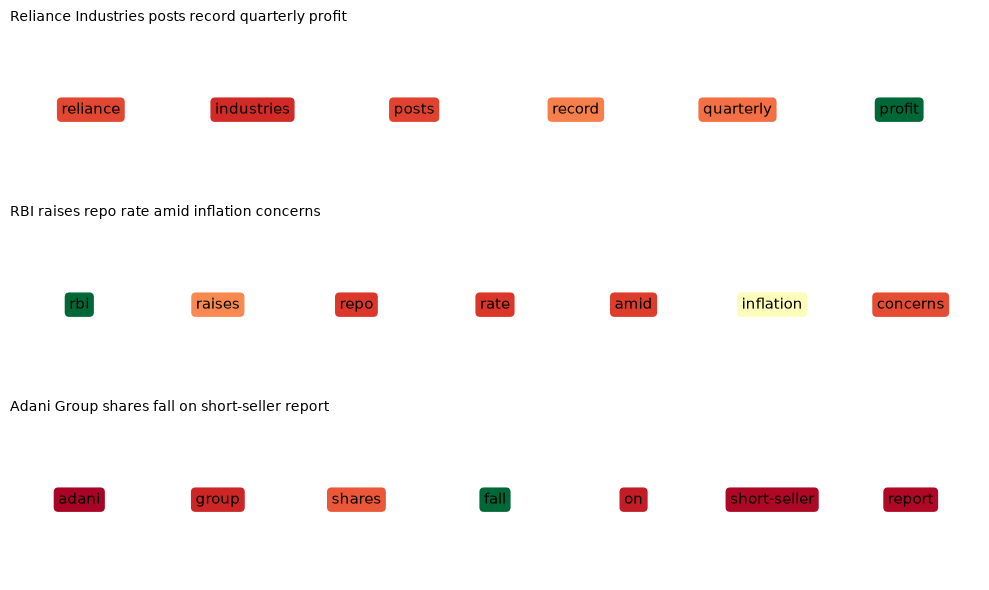

Saved attention visualization to: ./results/attention_viz.png


In [11]:
def plot_attention(model, tokenizer, text: str, ax=None):
    ids = tokenizer.encode(text)
    input_tensor = torch.tensor([ids], dtype=torch.long).to(DEVICE)

    weights = model.get_attention_weights(input_tensor)[0]   # (seq_len,)
    tokens = tokenizer._tokenize(text)
    weights = weights[: len(tokens)]                          # drop weight on PAD positions
    weights = weights / (weights.sum() + 1e-9)                # renormalize over real tokens only

    if ax is None:
        fig, ax = plt.subplots(figsize=(max(6, len(tokens) * 0.9), 1.5))

    ax.set_xlim(0, len(tokens))
    ax.set_ylim(0, 1)
    ax.axis("off")

    cmap = plt.cm.RdYlGn   # red (low attention) -> green (high attention)
    for i, (tok, w) in enumerate(zip(tokens, weights)):
        color = cmap(float(w) / (weights.max() + 1e-9))
        ax.text(i + 0.5, 0.5, tok, ha="center", va="center", fontsize=11,
                bbox=dict(boxstyle="round,pad=0.3", facecolor=color, edgecolor="none"))
    ax.set_title(text, fontsize=10, loc="left")


example_headlines = [
    "Reliance Industries posts record quarterly profit",
    "RBI raises repo rate amid inflation concerns",
    "Adani Group shares fall on short-seller report",
]

fig, axes = plt.subplots(len(example_headlines), 1, figsize=(10, 2 * len(example_headlines)))
for ax, headline in zip(axes, example_headlines):
    plot_attention(model, tokenizer, headline, ax=ax)
plt.tight_layout()

attn_viz_path = os.path.join(RESULTS_DIR, "attention_viz.png")
plt.savefig(attn_viz_path, dpi=120, bbox_inches="tight")
mlflow.log_artifact(attn_viz_path)
plt.show()
print(f"Saved attention visualization to: {attn_viz_path}")

mlflow.end_run()   # closes the baseline run — the HPT sections below open their own run(s)

## 8. Hyperparameter tuning (random search)

The baseline above uses one hand-picked config. Here we search over `embed_dim`, `conv_channels`,
`lstm_hidden`, `dropout`, `learning_rate`, `weight_decay`, and `batch_size` with a random search:
each of `N_TRIALS` trials trains a **fresh** model for a short `SEARCH_EPOCHS` budget (with its own
early stopping on val F1), and we keep the actual trained model object of whichever trial gets the
best val F1 — not just its config — so the next section can keep training that exact model instead
of reinitializing and losing what it already learned.

Honest expectation: classical ML topped out around 81% F1, and FinBERT+LoRA (a pretrained
transformer) reached ~86.5% F1. A from-scratch CNN-BiLSTM-Attention model trained on ~7,100 rows
reaching 90%+ would be a genuine surprise — worth searching for, but not assumed.

In [12]:
# ══════════════════════════════════════════════════════════════
# RANDOM SEARCH — Stage 1: short-budget trials, keep the best MODEL (not just config)
# ══════════════════════════════════════════════════════════════

SEARCH_SPACE = {
    "embed_dim": [64, 128, 200],
    "conv_channels": [64, 128, 200],
    "lstm_hidden": [64, 128, 200],
    "dropout": [0.2, 0.3, 0.4, 0.5],
    "learning_rate": [3e-4, 5e-4, 1e-3, 2e-3],
    "weight_decay": [0.0, 0.01, 0.05],
    "batch_size": [32, 64, 128],
}


def sample_config(rng: np.random.RandomState) -> dict:
    return {k: rng.choice(v) for k, v in SEARCH_SPACE.items()}


def build_loaders(batch_size: int):
    tl = DataLoader(SentimentDataset(train_df, tokenizer), batch_size=int(batch_size), shuffle=True)
    vl = DataLoader(SentimentDataset(val_df, tokenizer), batch_size=int(batch_size), shuffle=False)
    tel = DataLoader(SentimentDataset(test_df, tokenizer), batch_size=int(batch_size), shuffle=False)
    return tl, vl, tel


def run_trial(config: dict, epochs: int, patience: int) -> dict:
    tl, vl, tel = build_loaders(config["batch_size"])

    trial_model = CNNBiLSTMAttention(
        vocab_size=tokenizer.vocab_size_actual,
        embed_dim=int(config["embed_dim"]),
        conv_channels=int(config["conv_channels"]),
        lstm_hidden=int(config["lstm_hidden"]),
        num_classes=NUM_LABELS,
        dropout=float(config["dropout"]),
    ).to(DEVICE)

    optimizer = torch.optim.Adam(trial_model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"])
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    best_val_f1 = -1.0
    best_state = None
    epochs_no_improve = 0
    start = time.time()

    for epoch in range(1, epochs + 1):
        train_one_epoch(trial_model, tl, optimizer, criterion)
        _, val_metrics, _, _ = evaluate(trial_model, vl, criterion)

        if val_metrics["f1_weighted"] > best_val_f1:
            best_val_f1 = val_metrics["f1_weighted"]
            best_state = {k: v.detach().cpu().clone() for k, v in trial_model.state_dict().items()}
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                break

    trial_model.load_state_dict(best_state)
    train_time = time.time() - start

    return {
        "model": trial_model,
        "best_val_f1": best_val_f1,
        "train_time": train_time,
        "config": config,
        "train_loader": tl,
        "val_loader": vl,
        "test_loader": tel,
    }


N_TRIALS = 6
SEARCH_EPOCHS = 4
SEARCH_PATIENCE = 2

rng = np.random.RandomState(SEED)
trial_results = []
best_overall = None

print(f"Running {N_TRIALS} random-search trials ({SEARCH_EPOCHS} epochs each, patience={SEARCH_PATIENCE})...\n")
for trial_idx in range(1, N_TRIALS + 1):
    config = sample_config(rng)
    result = run_trial(config, epochs=SEARCH_EPOCHS, patience=SEARCH_PATIENCE)

    print(f"Trial {trial_idx}/{N_TRIALS} | config={config} | best_val_f1={result['best_val_f1']:.4f} | time={result['train_time']:.1f}s")

    trial_results.append({"trial": trial_idx, **result["config"], "best_val_f1": result["best_val_f1"], "train_time": result["train_time"]})

    if best_overall is None or result["best_val_f1"] > best_overall["best_val_f1"]:
        if best_overall is not None:
            del best_overall["model"]   # free the losing trial's model
        best_overall = result
    else:
        del result["model"]

leaderboard_df = pd.DataFrame(trial_results).sort_values("best_val_f1", ascending=False).reset_index(drop=True)
print("\n" + "=" * 70)
print("RANDOM SEARCH LEADERBOARD")
print("=" * 70)
print(leaderboard_df.to_string(index=False))

tuned_config = best_overall["config"]
tuned_model = best_overall["model"]
tuned_train_loader = best_overall["train_loader"]
tuned_val_loader = best_overall["val_loader"]
tuned_test_loader = best_overall["test_loader"]

print(f"\nBest config found: {tuned_config}")
print(f"Best val F1 (search stage): {best_overall['best_val_f1']:.4f}")

Running 6 random-search trials (4 epochs each, patience=2)...



Trial 1/6 | config={'embed_dim': np.int64(200), 'conv_channels': np.int64(64), 'lstm_hidden': np.int64(200), 'dropout': np.float64(0.4), 'learning_rate': np.float64(0.002), 'weight_decay': np.float64(0.0), 'batch_size': np.int64(32)} | best_val_f1=0.7907 | time=524.3s


Trial 2/6 | config={'embed_dim': np.int64(200), 'conv_channels': np.int64(128), 'lstm_hidden': np.int64(200), 'dropout': np.float64(0.4), 'learning_rate': np.float64(0.001), 'weight_decay': np.float64(0.05), 'batch_size': np.int64(32)} | best_val_f1=0.6947 | time=606.4s


Trial 3/6 | config={'embed_dim': np.int64(200), 'conv_channels': np.int64(128), 'lstm_hidden': np.int64(64), 'dropout': np.float64(0.3), 'learning_rate': np.float64(0.002), 'weight_decay': np.float64(0.01), 'batch_size': np.int64(64)} | best_val_f1=0.7507 | time=222.5s


Trial 4/6 | config={'embed_dim': np.int64(128), 'conv_channels': np.int64(64), 'lstm_hidden': np.int64(64), 'dropout': np.float64(0.5), 'learning_rate': np.float64(0.0005), 'weight_decay': np.float64(0.01), 'batch_size': np.int64(32)} | best_val_f1=0.7407 | time=164.8s


Trial 5/6 | config={'embed_dim': np.int64(64), 'conv_channels': np.int64(64), 'lstm_hidden': np.int64(200), 'dropout': np.float64(0.4), 'learning_rate': np.float64(0.001), 'weight_decay': np.float64(0.01), 'batch_size': np.int64(128)} | best_val_f1=0.7126 | time=327.2s


Trial 6/6 | config={'embed_dim': np.int64(128), 'conv_channels': np.int64(128), 'lstm_hidden': np.int64(200), 'dropout': np.float64(0.3), 'learning_rate': np.float64(0.001), 'weight_decay': np.float64(0.05), 'batch_size': np.int64(32)} | best_val_f1=0.6745 | time=542.1s

RANDOM SEARCH LEADERBOARD
 trial  embed_dim  conv_channels  lstm_hidden  dropout  learning_rate  weight_decay  batch_size  best_val_f1  train_time
     1        200             64          200      0.4         0.0020          0.00          32       0.7907  524.265432
     3        200            128           64      0.3         0.0020          0.01          64       0.7507  222.504118
     4        128             64           64      0.5         0.0005          0.01          32       0.7407  164.773000
     5         64             64          200      0.4         0.0010          0.01         128       0.7126  327.166525
     2        200            128          200      0.4         0.0010          0.05          32  

## 9. Continue training the winning model for a full epoch budget

We do **not** reinitialize the winning model — it already learned something during the search.
We continue training that exact model object for up to `FINAL_EPOCHS` epochs at half its search
learning rate, with early stopping on val F1 (patience `FINAL_PATIENCE`). Every single epoch prints
train/val/test accuracy AND F1 (test is purely informational — the early-stopping decision only
ever looks at val F1).

Continuing training of the winning model (lr=0.001000) for up to 20 epochs...

 Epoch | train_acc  train_f1 |   val_acc    val_f1 |  test_acc   test_f1
------------------------------------------------------------------------------


     1 |    0.9932    0.9932 |    0.7960    0.7957 |    0.7618    0.7616


     2 |    0.9955    0.9955 |    0.7886    0.7882 |    0.7590    0.7578


     3 |    0.9982    0.9982 |    0.7717    0.7713 |    0.7555    0.7551


     4 |    0.9993    0.9993 |    0.7970    0.7970 |    0.7590    0.7587


...

    15 |    0.9973    0.9973 |    0.7685    0.7670 |    0.7442    0.7420


    16 |    0.9999    0.9999 |    0.7918    0.7916 |    0.7639    0.7635


    17 |    1.0000    1.0000 |    0.7822    0.7820 |    0.7653    0.7649


    18 |    0.9999    0.9999 |    0.7844    0.7844 |    0.7660    0.7659


    19 |    1.0000    1.0000 |    0.7727    0.7717 |    0.7604    0.7597

Early stopping at epoch 19 (no val F1 improvement for 5 epochs).


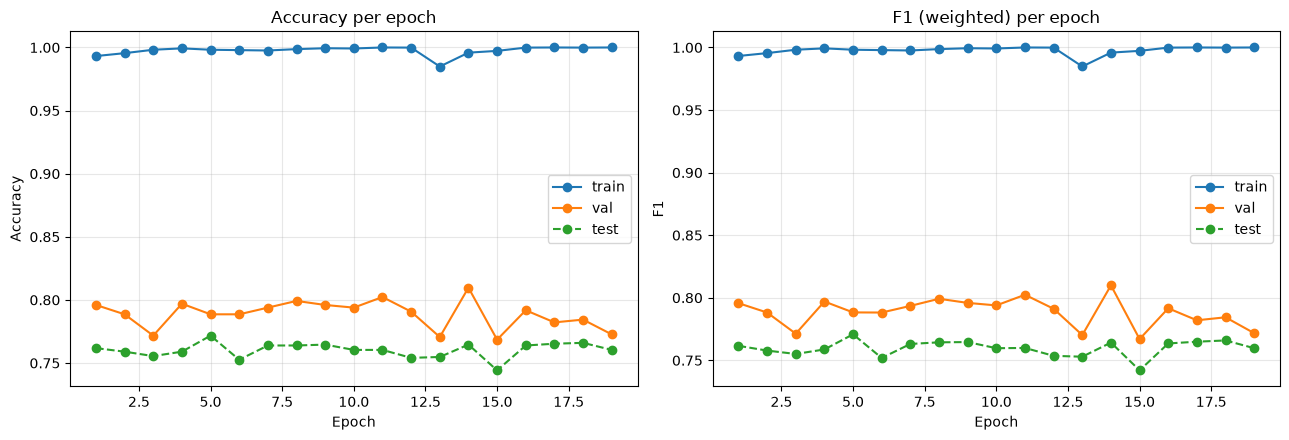


Best val F1 (final stage): 0.8099 | Continued-training time: 2382.8s


In [13]:
# ══════════════════════════════════════════════════════════════
# STAGE 2 — continue training the winning model, full epoch budget, full visibility
# ══════════════════════════════════════════════════════════════

FINAL_EPOCHS = 20
FINAL_PATIENCE = 5
FINAL_LR = tuned_config["learning_rate"] * 0.5

tuned_optimizer = torch.optim.Adam(tuned_model.parameters(), lr=FINAL_LR, weight_decay=tuned_config["weight_decay"])
tuned_criterion = nn.CrossEntropyLoss(weight=class_weights)

best_val_f1 = -1.0
best_state = None
epochs_no_improve = 0
history = []
start = time.time()

print(f"Continuing training of the winning model (lr={FINAL_LR:.6f}) for up to {FINAL_EPOCHS} epochs...\n")
print(f"{'Epoch':>6} | {'train_acc':>9} {'train_f1':>9} | {'val_acc':>9} {'val_f1':>9} | {'test_acc':>9} {'test_f1':>9}")
print("-" * 78)

for epoch in range(1, FINAL_EPOCHS + 1):
    train_one_epoch(tuned_model, tuned_train_loader, tuned_optimizer, tuned_criterion)

    _, train_metrics, _, _ = evaluate(tuned_model, tuned_train_loader, tuned_criterion)
    _, val_metrics, _, _ = evaluate(tuned_model, tuned_val_loader, tuned_criterion)
    _, test_metrics_epoch, _, _ = evaluate(tuned_model, tuned_test_loader, tuned_criterion)

    train_acc, train_f1 = train_metrics["accuracy"], train_metrics["f1_weighted"]
    val_acc, val_f1 = val_metrics["accuracy"], val_metrics["f1_weighted"]
    test_acc, test_f1 = test_metrics_epoch["accuracy"], test_metrics_epoch["f1_weighted"]

    print(f"{epoch:>6} | {train_acc:>9.4f} {train_f1:>9.4f} | {val_acc:>9.4f} {val_f1:>9.4f} | {test_acc:>9.4f} {test_f1:>9.4f}")

    history.append({"epoch": epoch, "train_acc": train_acc, "train_f1": train_f1,
                     "val_acc": val_acc, "val_f1": val_f1, "test_acc": test_acc, "test_f1": test_f1})

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_state = {k: v.detach().cpu().clone() for k, v in tuned_model.state_dict().items()}
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= FINAL_PATIENCE:
            print(f"\nEarly stopping at epoch {epoch} (no val F1 improvement for {FINAL_PATIENCE} epochs).")
            break

tuned_train_time = time.time() - start
tuned_model.load_state_dict(best_state)   # restore the best-val-F1 checkpoint

history_df = pd.DataFrame(history)
history_path = os.path.join(RESULTS_DIR, f"history_{MODEL_NAME.lower().replace(' ', '_').replace('-', '_')}_tuned.csv")
history_df.to_csv(history_path, index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(history_df["epoch"], history_df["train_acc"], label="train", marker="o")
axes[0].plot(history_df["epoch"], history_df["val_acc"], label="val", marker="o")
axes[0].plot(history_df["epoch"], history_df["test_acc"], label="test", marker="o", linestyle="--")
axes[0].set_title("Accuracy per epoch"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history_df["epoch"], history_df["train_f1"], label="train", marker="o")
axes[1].plot(history_df["epoch"], history_df["val_f1"], label="val", marker="o")
axes[1].plot(history_df["epoch"], history_df["test_f1"], label="test", marker="o", linestyle="--")
axes[1].set_title("F1 (weighted) per epoch"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("F1"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
curve_path = os.path.join(RESULTS_DIR, f"training_curve_{MODEL_NAME.lower().replace(' ', '_').replace('-', '_')}_tuned.png")
plt.savefig(curve_path, dpi=120, bbox_inches="tight")
plt.show()

print(f"\nBest val F1 (final stage): {best_val_f1:.4f} | Continued-training time: {tuned_train_time:.1f}s")

In [14]:
# ══════════════════════════════════════════════════════════════
# FINAL COMPARISON — baseline vs HPT-tuned, and the 90% verdict
# ══════════════════════════════════════════════════════════════

tuned_test_loss, tuned_test_metrics, tuned_test_preds, tuned_test_labels = evaluate(tuned_model, tuned_test_loader, tuned_criterion)
tuned_n_params = count_parameters(tuned_model)

comparison_df = pd.DataFrame([
    {"variant": "baseline", "accuracy": test_metrics["accuracy"], "f1_weighted": test_metrics["f1_weighted"], "params": n_params},
    {"variant": "HPT_tuned", "accuracy": tuned_test_metrics["accuracy"], "f1_weighted": tuned_test_metrics["f1_weighted"], "params": tuned_n_params},
])
print("=" * 60)
print("BASELINE vs HPT-TUNED — TEST SET")
print("=" * 60)
print(comparison_df.to_string(index=False))

final_model, final_variant, final_test_metrics = tuned_model, "HPT_tuned", tuned_test_metrics

cm_path_tuned = save_confusion_matrix(tuned_test_labels, tuned_test_preds, f"{MODEL_NAME}_tuned")

print(f"\n{'='*60}")
if final_test_metrics["accuracy"] >= 0.90 and final_test_metrics["f1_weighted"] >= 0.90:
    print(f">>> 90%+ ACHIEVED: accuracy={final_test_metrics['accuracy']:.4f}, f1_weighted={final_test_metrics['f1_weighted']:.4f}")
else:
    print(f">>> Did NOT reach 90%: accuracy={final_test_metrics['accuracy']:.4f}, f1_weighted={final_test_metrics['f1_weighted']:.4f}")
print(f"{'='*60}")

mlflow.start_run(run_name=f"{MODEL_NAME}_HPT_tuned")
mlflow.log_params({
    "model": MODEL_NAME, "variant": "HPT_tuned",
    "embed_dim": int(tuned_config["embed_dim"]), "conv_channels": int(tuned_config["conv_channels"]),
    "lstm_hidden": int(tuned_config["lstm_hidden"]), "dropout": float(tuned_config["dropout"]),
    "learning_rate": FINAL_LR, "weight_decay": tuned_config["weight_decay"],
    "batch_size": int(tuned_config["batch_size"]), "max_length": MAX_LENGTH,
})
for k, v in tuned_test_metrics.items():
    mlflow.log_metric(f"test_{k}", v)
mlflow.log_metric("train_time_seconds", round(tuned_train_time, 2))
mlflow.log_metric("param_count", tuned_n_params)
mlflow.log_artifact(cm_path_tuned)
mlflow.log_artifact(history_path)
mlflow.log_artifact(curve_path)
mlflow.end_run()

print("\nLogged HPT-tuned run to MLflow.")

BASELINE vs HPT-TUNED — TEST SET
  variant  accuracy  f1_weighted  params
 baseline    0.7259       0.7265 1510660
HPT_tuned    0.7646       0.7642 2334396



>>> Did NOT reach 90%: accuracy=0.7646, f1_weighted=0.7642

Logged HPT-tuned run to MLflow.


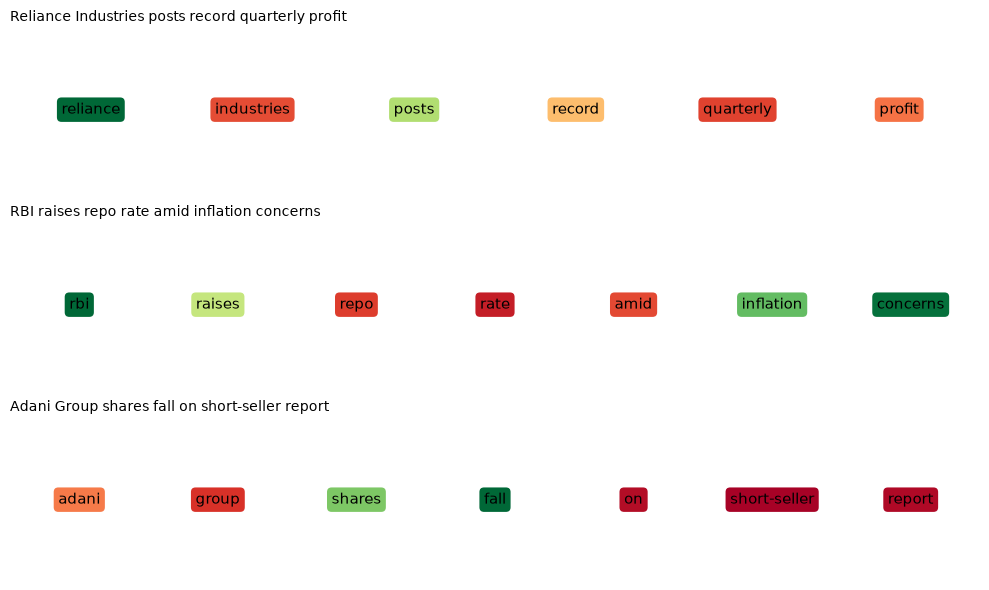

Saved tuned-model attention visualization to: ./results/attention_viz_tuned.png


In [15]:
# ── re-run attention visualization on the HPT-tuned model ────────
fig, axes = plt.subplots(len(example_headlines), 1, figsize=(10, 2 * len(example_headlines)))
for ax, headline in zip(axes, example_headlines):
    plot_attention(final_model, tokenizer, headline, ax=ax)
plt.tight_layout()

attn_viz_tuned_path = os.path.join(RESULTS_DIR, "attention_viz_tuned.png")
plt.savefig(attn_viz_tuned_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Saved tuned-model attention visualization to: {attn_viz_tuned_path}")

## 10. Save model + tokenizer for local download

In [16]:
# ── save model + tokenizer for local download ────────────────────
tuned_model_config = {
    "vocab_size": tokenizer.vocab_size_actual,
    "embed_dim": int(tuned_config["embed_dim"]),
    "conv_channels": int(tuned_config["conv_channels"]),
    "lstm_hidden": int(tuned_config["lstm_hidden"]),
    "num_classes": NUM_LABELS,
    "dropout": float(tuned_config["dropout"]),
}

model_path = os.path.join(MODELS_DIR, "cnn_bilstm_attention.pt")
torch.save({
    "model_state_dict": final_model.state_dict(),
    "config": tuned_model_config,
    "test_metrics": final_test_metrics,
    "variant": final_variant,
}, model_path)

tok_path = os.path.join(MODELS_DIR, "tokenizer.pkl")
with open(tok_path, "wb") as f:
    pickle.dump(tokenizer, f)

mlflow.log_artifact(model_path)

print(f"\nSaved model to: {model_path}")
print(f"Saved tokenizer to: {tok_path}")
print(f"\nDownload these from the Kaggle notebook's Output tab before your session ends:")
print(f"  - {MODELS_DIR}/  (trained model + tokenizer)")
print(f"  - {RESULTS_DIR}/  (confusion matrix, report, training curves, attention viz)")
print(f"  - {os.path.join(BASE_DIR, 'mlflow.db')}  (all MLflow metrics/params — NOT just the mlruns/ folder!)")
print(f"  - {os.path.join(BASE_DIR, 'mlruns')}/  (MLflow artifacts)")


Saved model to: ./saved_models/cnn_bilstm_attention.pt
Saved tokenizer to: ./saved_models/tokenizer.pkl

Download these from the Kaggle notebook's Output tab before your session ends:
  - ./saved_models/  (trained model + tokenizer)
  - ./results/  (confusion matrix, report, training curves, attention viz)
  - ./mlflow.db  (all MLflow metrics/params — NOT just the mlruns/ folder!)
  - ./mlruns/  (MLflow artifacts)
